In [1]:
%pip install "opencv-python==5.0.0.*" "opencv-contrib-python==5.0.0.*" ultralytics matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Importing the library

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Setup completed successfully!")

OpenCV version: 5.0.0
NumPy version: 2.4.6
Setup completed successfully!


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in the current folder:")
print(os.listdir())

print("\nDoes data/images exist?")
print(os.path.exists("data/images"))

Current working directory:
d:\Python_rnw\one\deep learning\pr3

Files in the current folder:
['CV_PR3.ipynb', 'data', 'models', 'plots', 'sample.jpg', 'yolov8n.pt']

Does data/images exist?
True


In [4]:
import os

# Create folders for the PR3 project
os.makedirs("data/images", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

print("Project folders created successfully!")
print("Images folder exists:", os.path.exists("data/images"))
print("Models folder exists:", os.path.exists("models"))
print("Plots folder exists:", os.path.exists("plots"))

Project folders created successfully!
Images folder exists: True
Models folder exists: True
Plots folder exists: True


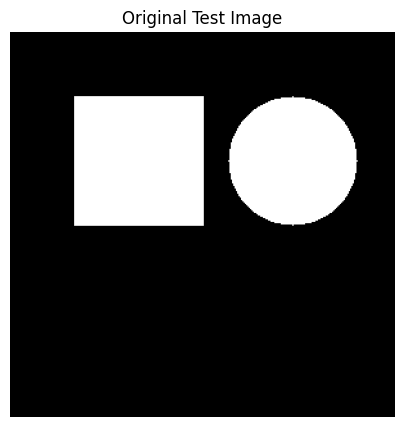

In [5]:
# Create a simple test image
image = np.zeros((300, 300), dtype=np.uint8)

# Draw white shapes on a black background
cv2.rectangle(image, (50, 50), (150, 150), 255, -1)
cv2.circle(image, (220, 100), 50, 255, -1)

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Test Image")
plt.axis("off")
plt.show()

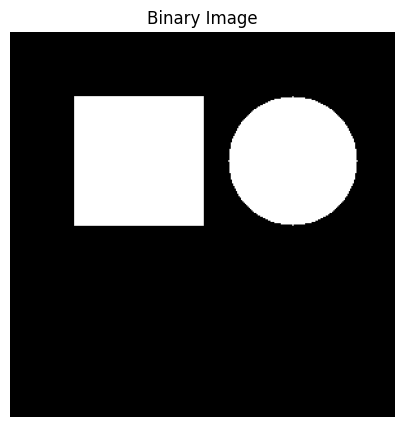

Threshold value: 127.0
Unique pixel values: [  0 255]


In [6]:

# Convert the image to binary using thresholding
threshold_value, binary_image = cv2.threshold(
    image, 127, 255, cv2.THRESH_BINARY
)

# Display the binary image
plt.figure(figsize=(5, 5))
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

print("Threshold value:", threshold_value)
print("Unique pixel values:", np.unique(binary_image))

In [7]:
cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)

(127.0,
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(300, 300), dtype=uint8))

Threshold value: 127.0
Image shape: (300, 300)
Unique pixel values: [  0 255]


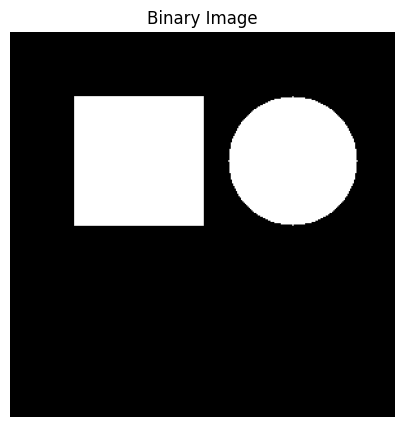

In [8]:

print("Threshold value:", threshold_value)
print("Image shape:", binary_image.shape)
print("Unique pixel values:", np.unique(binary_image))

plt.figure(figsize=(5, 5))
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

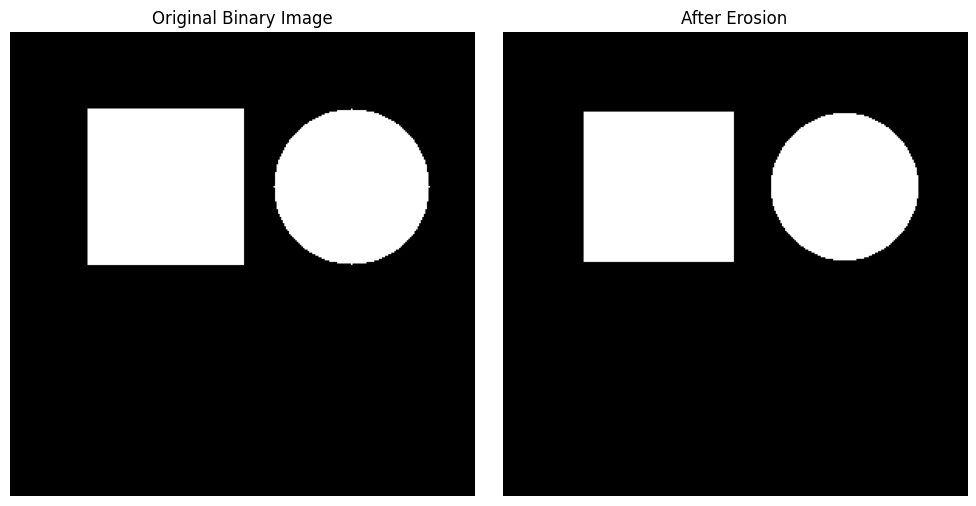

In [9]:

# Create a 5 x 5 kernel
kernel = np.ones((5, 5), dtype=np.uint8)

# Apply erosion
eroded_image = cv2.erode(binary_image, kernel, iterations=1)

# Display original and eroded images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eroded_image, cmap="gray")
plt.title("After Erosion")
plt.axis("off")

plt.tight_layout()
plt.show()

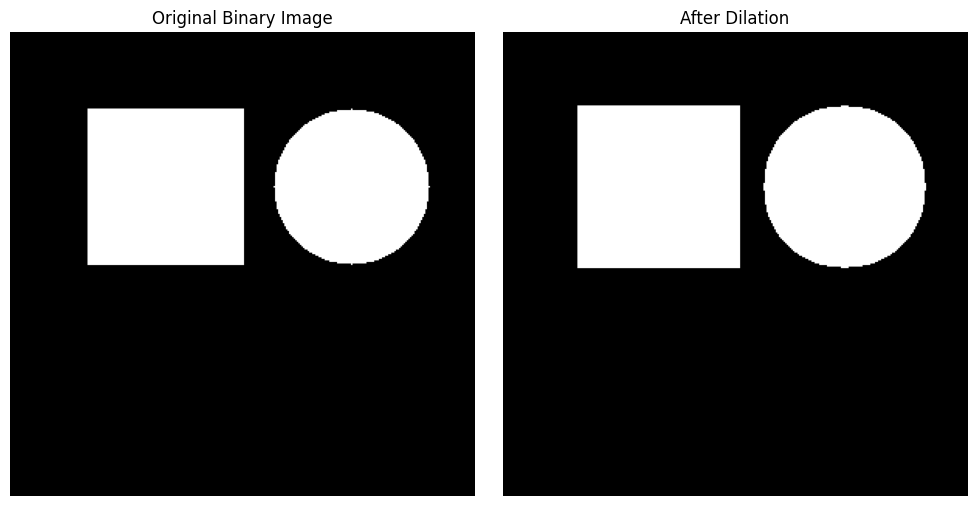

In [10]:

# Apply dilation
dilated_image = cv2.dilate(binary_image, kernel, iterations=1)

# Display original and dilated images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dilated_image, cmap="gray")
plt.title("After Dilation")
plt.axis("off")

plt.tight_layout()
plt.show()

Apply opening

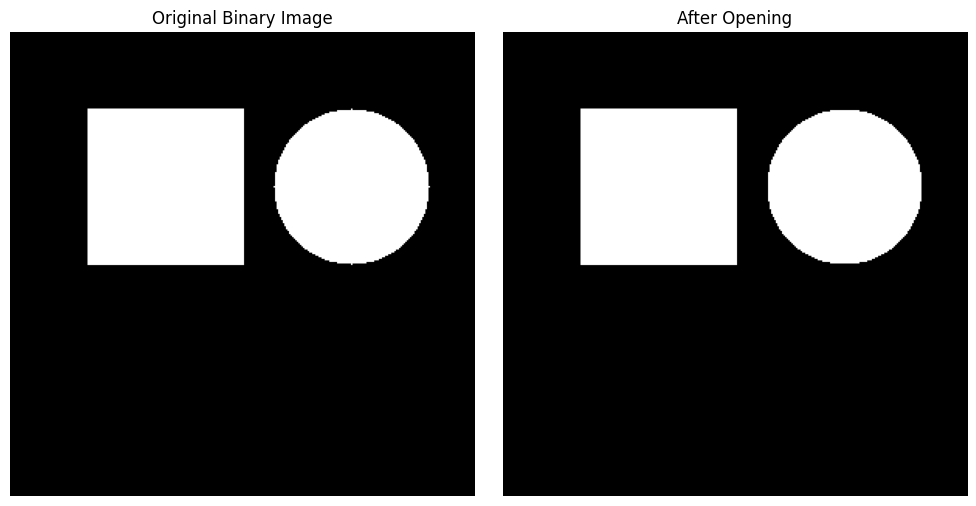

In [11]:

# Apply morphological opening
opening_image = cv2.morphologyEx(
    binary_image,
    cv2.MORPH_OPEN,
    kernel
)

# Display the original and opened images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(opening_image, cmap="gray")
plt.title("After Opening")
plt.axis("off")

plt.tight_layout()
plt.show()

Apply closing

Closing = Dilation followed by Erosion.

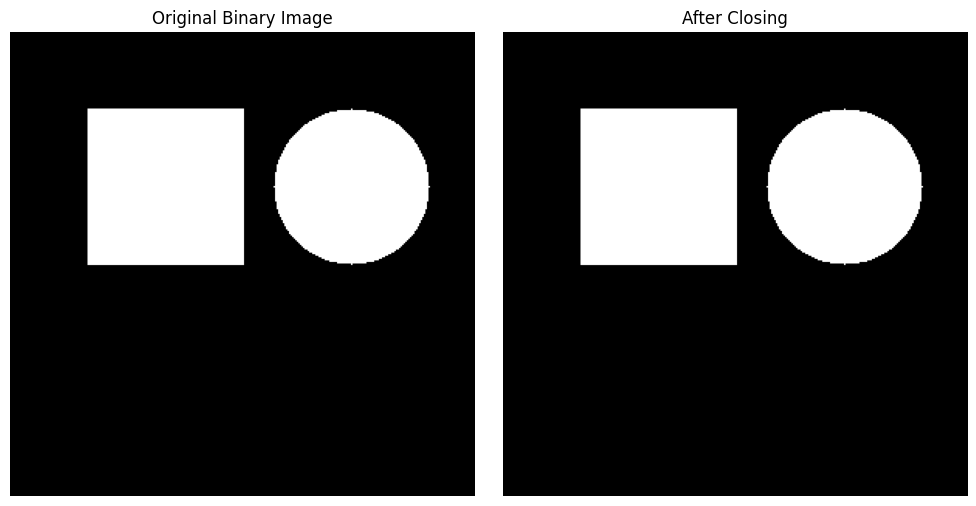

In [12]:

# Apply morphological closing
closing_image = cv2.morphologyEx(
    binary_image,
    cv2.MORPH_CLOSE,
    kernel
)

# Display the original and closed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary_image, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(closing_image, cmap="gray")
plt.title("After Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

Compare kernel shapes and sizes

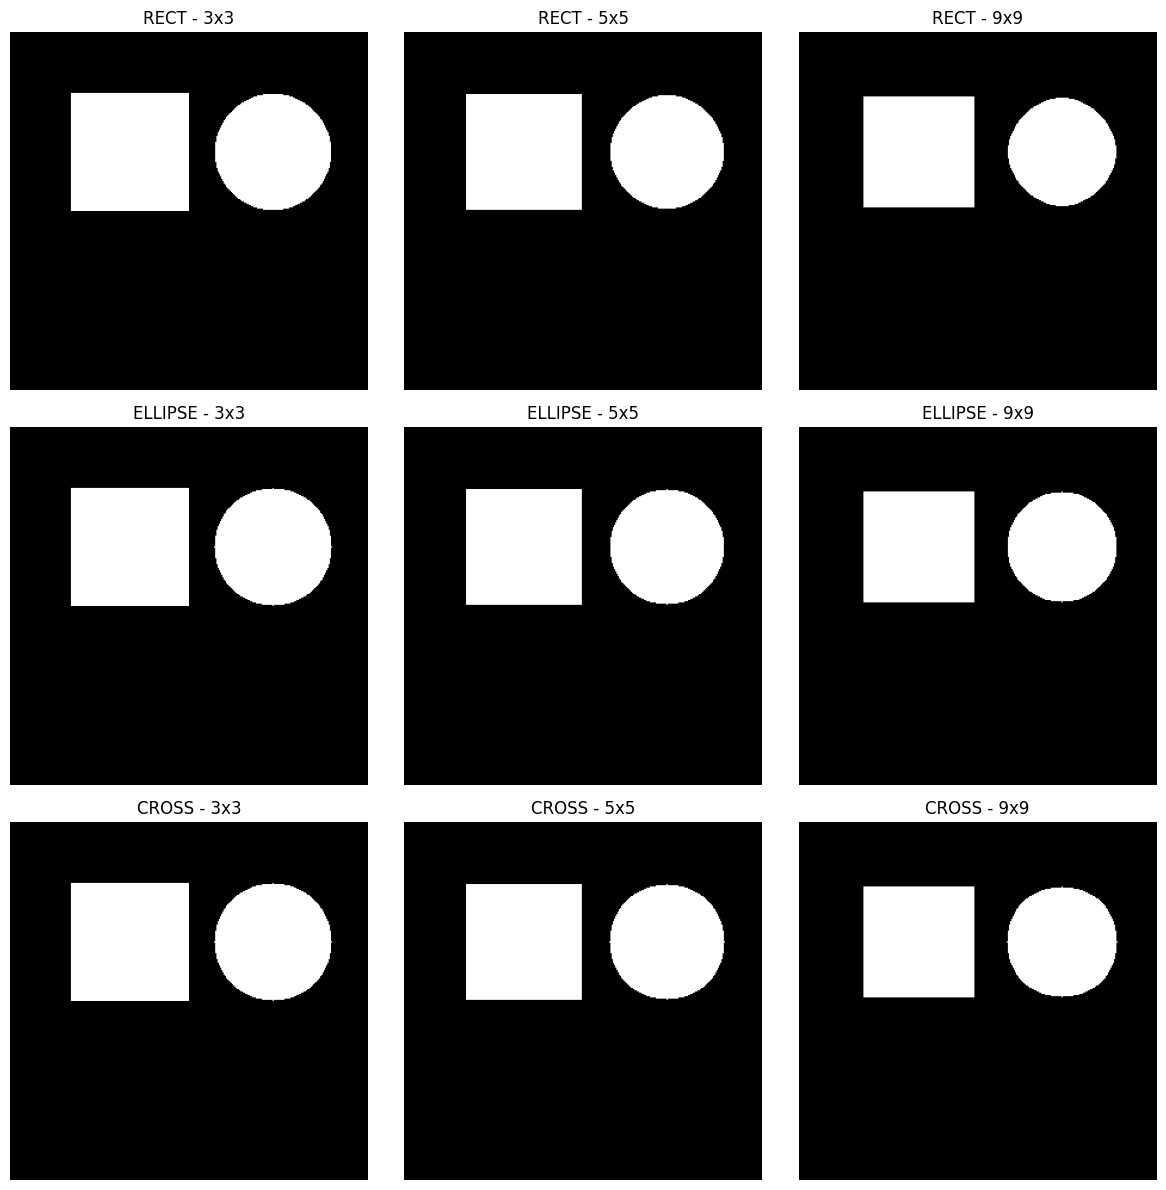

In [13]:

# Define kernel shapes and sizes
kernel_shapes = {
    "RECT": cv2.MORPH_RECT,
    "ELLIPSE": cv2.MORPH_ELLIPSE,
    "CROSS": cv2.MORPH_CROSS
}

kernel_sizes = [3, 5, 9]

# Display erosion results for all 9 combinations
plt.figure(figsize=(12, 12))

plot_index = 1

for shape_name, shape_code in kernel_shapes.items():
    for size in kernel_sizes:

        # Create the kernel
        test_kernel = cv2.getStructuringElement(
            shape_code, (size, size)
        )

        # Apply erosion
        result = cv2.erode(
            binary_image, test_kernel, iterations=1
        )

        # Display the result
        plt.subplot(3, 3, plot_index)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}x{size}")
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

### Observations: Effect of Kernel Shape and Size

* **Kernel size:** As the kernel size increases from 3×3 to 9×9, erosion removes more pixels from the boundaries of the white objects, making them smaller.
* **RECT kernel:** Erodes the objects using a rectangular neighborhood.
* **ELLIPSE kernel:** Uses an elliptical neighborhood and can produce smoother boundary effects on rounded objects.
* **CROSS kernel:** Uses a cross-shaped neighborhood, emphasizing horizontal and vertical pixels.
* **Conclusion:** Both kernel shape and kernel size affect the result of morphological operations. Larger kernels generally produce stronger erosion.


Image 

In [14]:
import urllib.request
import os

image_folder = "data/images"
image_path = os.path.join(image_folder, "sample.jpg")

url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"

try:
    urllib.request.urlretrieve(url, image_path)
    print("Image downloaded successfully!")
except Exception as e:
    print("Download failed:", e)

print("Files in images folder:", os.listdir(image_folder))

Image downloaded successfully!
Files in images folder: ['group.jpg', 'messi5.jpg', 'people.jpg', 'people_group.jpg', 'sample.jpg', 'side_face.jpg']


In [15]:

# Load the sample image in colour and grayscale
image_path = "data/images/sample.jpg"

color_image = cv2.imread(image_path)
gray_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Check that both images loaded successfully
if color_image is None or gray_image is None:
    print("Image loading failed. Check the image path.")
else:
    print("Colour image shape:", color_image.shape)
    print("Colour image dtype:", color_image.dtype)

    print("Grayscale image shape:", gray_image.shape)
    print("Grayscale image dtype:", gray_image.dtype)

Colour image shape: (512, 512, 3)
Colour image dtype: uint8
Grayscale image shape: (512, 512)
Grayscale image dtype: uint8


Create the show(img, title) helper

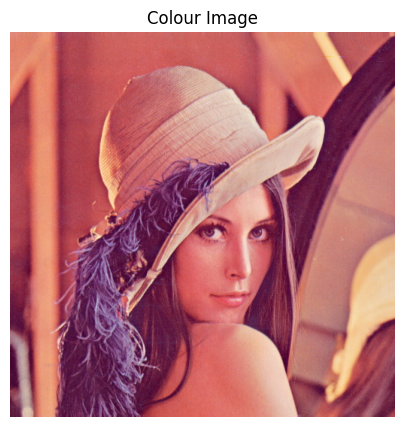

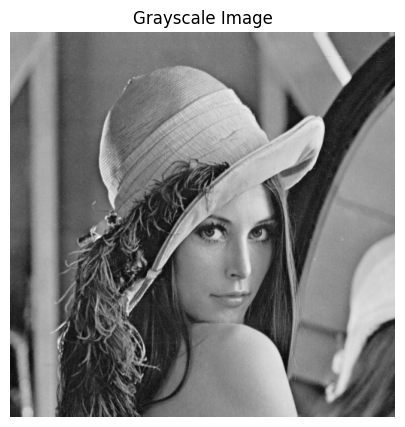

In [16]:

def show(img, title="Image"):
    # Create a figure
    plt.figure(figsize=(6, 5))

    # Check whether the image is grayscale or colour
    if len(img.shape) == 3:
        # Convert BGR to RGB for correct colours
        display_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(display_img)
    else:
        # Display grayscale image
        plt.imshow(img, cmap="gray")

    plt.title(title)
    plt.axis("off")
    plt.show()


# Test the function
show(color_image, "Colour Image")
show(gray_image, "Grayscale Image")

## Binarize a Test Image.

Convert the colour image to grayscale

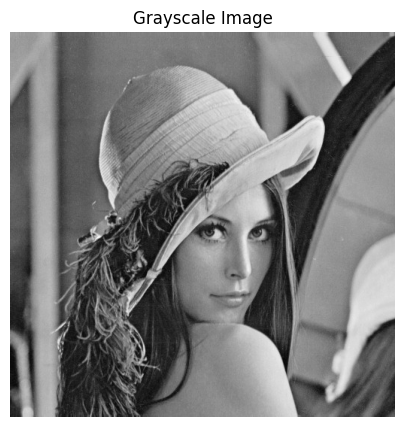

In [17]:
gray_from_color = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)

show(gray_from_color, "Grayscale Image")

Convert the grayscale image into a binary image

In [18]:
threshold_value, binary_image = cv2.threshold(
    gray_from_color,
    127,
    255,
    cv2.THRESH_BINARY
)

print("Threshold value:", threshold_value)
print("Binary image shape:", binary_image.shape)
print("Unique pixel values:", np.unique(binary_image))

Threshold value: 127.0
Binary image shape: (512, 512)
Unique pixel values: [  0 255]


Display both images side by side

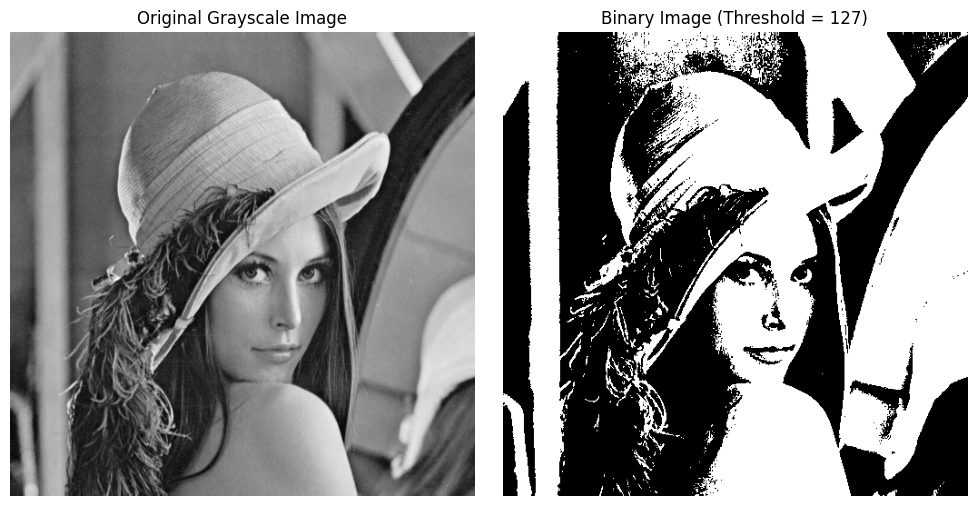

In [19]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_from_color, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image (Threshold = 127)")
plt.axis("off")

plt.tight_layout()
plt.show()

## Task 1.3 — Four Morphological Operations

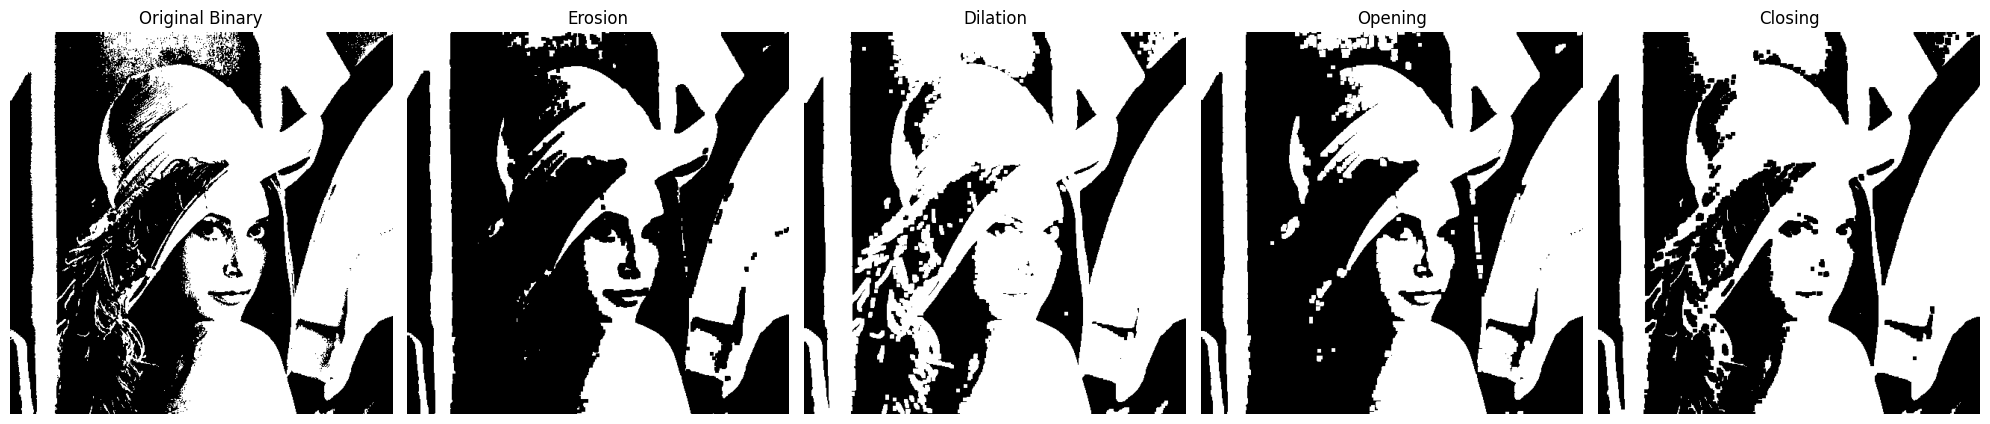

In [20]:
# Create the kernel
kernel = np.ones((5, 5), dtype=np.uint8)

# Apply morphological operations
eroded_image = cv2.erode(binary_image, kernel, iterations=1)

dilated_image = cv2.dilate(binary_image, kernel, iterations=1)

opening_image = cv2.morphologyEx(
    binary_image, cv2.MORPH_OPEN, kernel
)

closing_image = cv2.morphologyEx(
    binary_image, cv2.MORPH_CLOSE, kernel
)

# Display all five images in a 1 × 5 grid
images = [
    binary_image,
    eroded_image,
    dilated_image,
    opening_image,
    closing_image
]

titles = [
    "Original Binary",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(20, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

Erosion: White regions shrink, and some small white details disappear.

Dilation: White regions expand and some black gaps become smaller.

Opening: Removes some small white details while preserving much of the overall structure.

Closing: Fills some small black gaps, although the effect depends on the image and kernel.

## Task 1.4 — Kernel shape and size on a noisy binary image

Add noise to the binary image

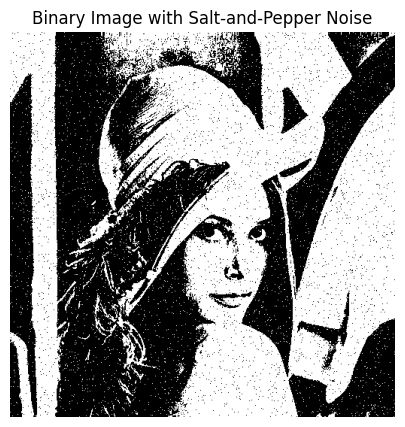

In [21]:
# Create a copy of the binary image
noisy_binary = binary_image.copy()

# Set a random seed so the result is reproducible
np.random.seed(42)

# Add salt-and-pepper noise
noise = np.random.random(binary_image.shape)

# Salt: randomly change some pixels to white
noisy_binary[noise < 0.02] = 255

# Pepper: randomly change some pixels to black
noisy_binary[(noise >= 0.02) & (noise < 0.04)] = 0

# Display the noisy image
show(noisy_binary, "Binary Image with Salt-and-Pepper Noise")

Salt noise adds random white pixels.

Pepper noise adds random black pixels.

We're changing approximately 4% of the pixels in total.

Compare kernel shapes and sizes

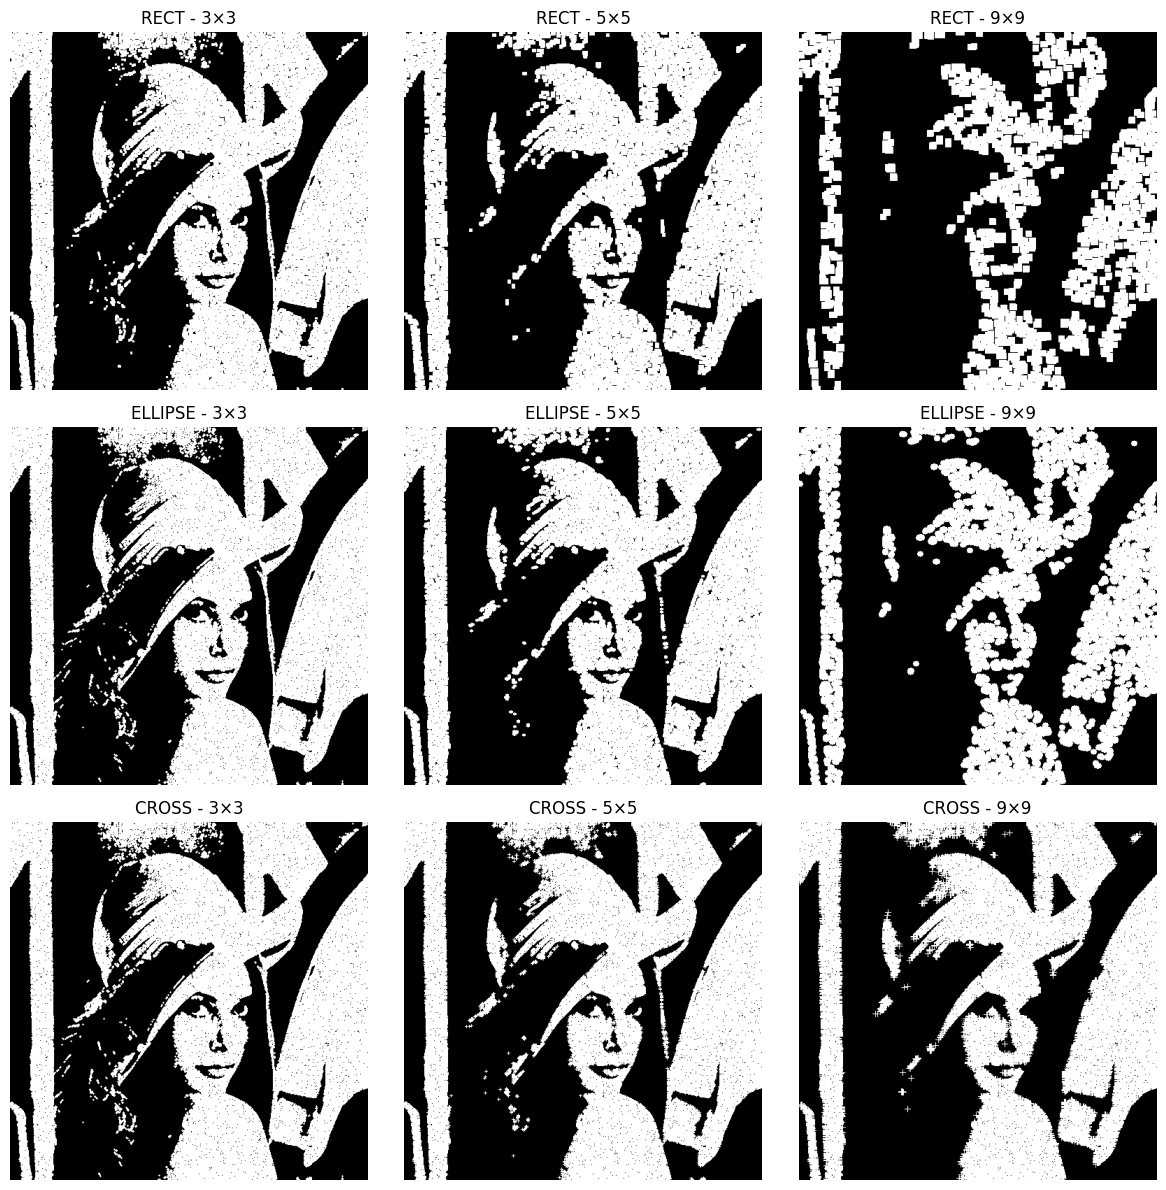

In [22]:
# Define three kernel shapes
kernel_shapes = {
    "RECT": cv2.MORPH_RECT,
    "ELLIPSE": cv2.MORPH_ELLIPSE,
    "CROSS": cv2.MORPH_CROSS
}

# Define three kernel sizes
kernel_sizes = [3, 5, 9]

# Display results in a 3 × 3 grid
plt.figure(figsize=(12, 12))

plot_index = 1

for shape_name, shape_code in kernel_shapes.items():
    for size in kernel_sizes:

        # Create the structuring element
        test_kernel = cv2.getStructuringElement(
            shape_code, (size, size)
        )

        # Apply opening to the noisy image
        result = cv2.morphologyEx(
            noisy_binary, cv2.MORPH_OPEN, test_kernel
        )

        plt.subplot(3, 3, plot_index)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}×{size}")
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

RECT: a square-shaped kernel.

ELLIPSE: a rounded kernel.

CROSS: a cross-shaped kernel.

3×3: smaller changes, potentially preserving more detail.

5×5: stronger noise removal, with some detail loss possible.

9×9: stronger changes, but fine parts of the image may disappear.

Compare closing

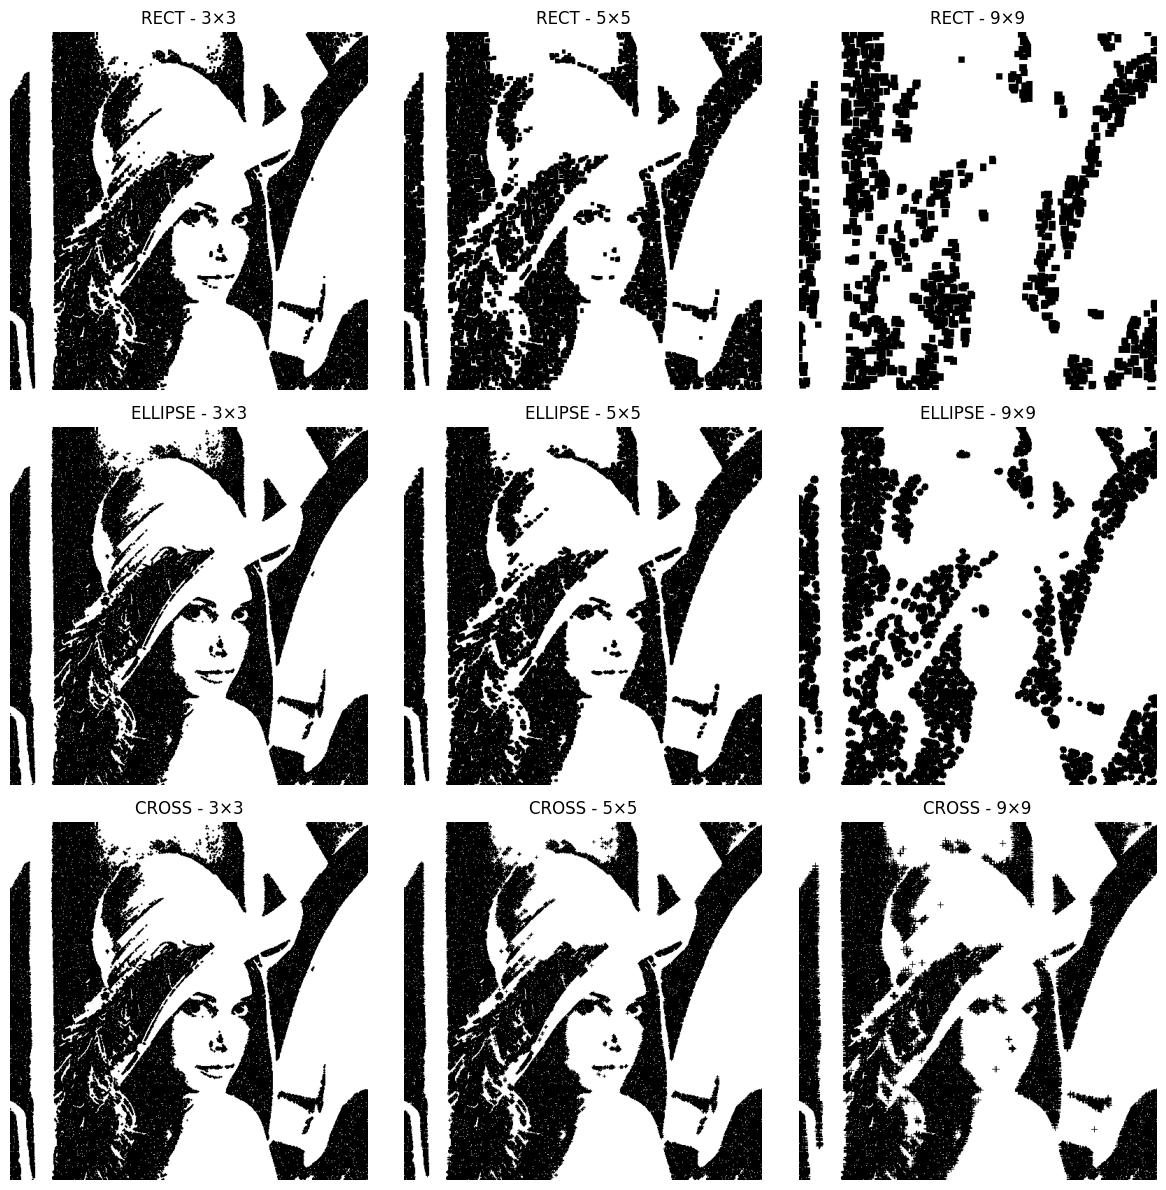

In [23]:
plt.figure(figsize=(12, 12))

plot_index = 1

for shape_name, shape_code in kernel_shapes.items():
    for size in kernel_sizes:

        # Create the structuring element
        test_kernel = cv2.getStructuringElement(
            shape_code, (size, size)
        )

        # Apply closing to the noisy image
        result = cv2.morphologyEx(
            noisy_binary, cv2.MORPH_CLOSE, test_kernel
        )

        plt.subplot(3, 3, plot_index)
        plt.imshow(result, cmap="gray")
        plt.title(f"{shape_name} - {size}×{size}")
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

### Observations: Effect of Kernel Shape and Size

* **Kernel size:** The 3×3 kernel preserves more fine details, while the 9×9 kernel changes the image more aggressively and can damage important outlines.
* **RECT:** Uses a rectangular structuring element and can produce stronger changes to square-shaped regions.
* **ELLIPSE:** Uses a rounded structuring element and follows curved boundaries more naturally.
* **CROSS:** Uses a cross-shaped structuring element and affects pixels mainly along horizontal and vertical directions.
* **Opening:** Helps remove small white noise from the image.
* **Closing:** Helps fill small black gaps and holes.

**Conclusion:** The best kernel depends on the image and the amount of noise. A smaller kernel may preserve object outlines better, while a larger kernel may remove more noise but also destroy useful details.


### Task 1.5: Explanation of Morphological Operations

**1. Erosion**

Erosion is similar to a local minimum filter for a binary image. It shrinks white regions and can remove small white noise. It is useful for removing tiny unwanted foreground objects before object detection.

**2. Dilation**

Dilation is similar to a local maximum filter for a binary image. It expands white regions and can fill small gaps between nearby white pixels. It is useful for reconnecting broken parts of an object in a segmentation mask.

**3. Opening**

Opening consists of erosion followed by dilation. It helps remove small white objects and noise while preserving the general shape of larger objects. For example, it can clean a binary mask before passing it to an object detector.

**4. Closing**

Closing consists of dilation followed by erosion. It helps fill small black holes and gaps inside white regions. For example, it can fill small gaps in a detected object mask before further image processing.

**Conclusion**

Morphological operations modify the shape and structure of foreground regions in binary images. The choice of operation and kernel size depends on the type of noise and the details that must be preserved. A kernel that is too large may remove important parts of an object.


## Task 2: Bitwise Operations & Image Histograms

Task 2.1 — Bitwise AND, OR, XOR and NOT

Create two binary masks

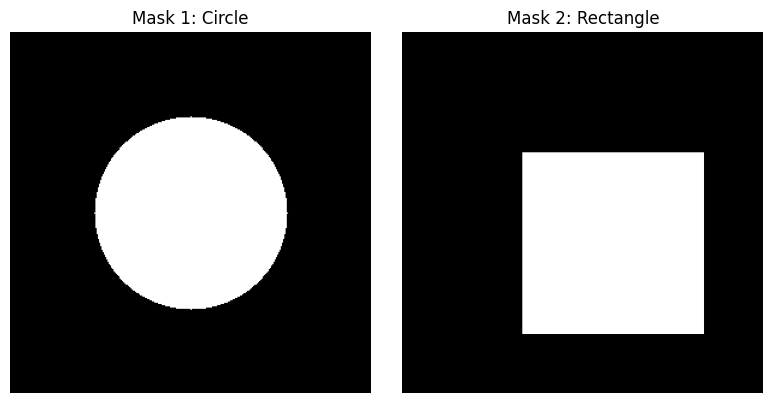

In [24]:
# Create a blank black canvas
mask1 = np.zeros((300, 300), dtype=np.uint8)
mask2 = np.zeros((300, 300), dtype=np.uint8)

# Draw a white circle on the first mask
cv2.circle(mask1, (150, 150), 80, 255, -1)

# Draw a white rectangle on the second mask
cv2.rectangle(mask2, (100, 100), (250, 250), 255, -1)

# Display both masks
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(mask1, cmap="gray")
plt.title("Mask 1: Circle")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask2, cmap="gray")
plt.title("Mask 2: Rectangle")
plt.axis("off")

plt.tight_layout()
plt.show()

Apply AND, OR, XOR and NOT

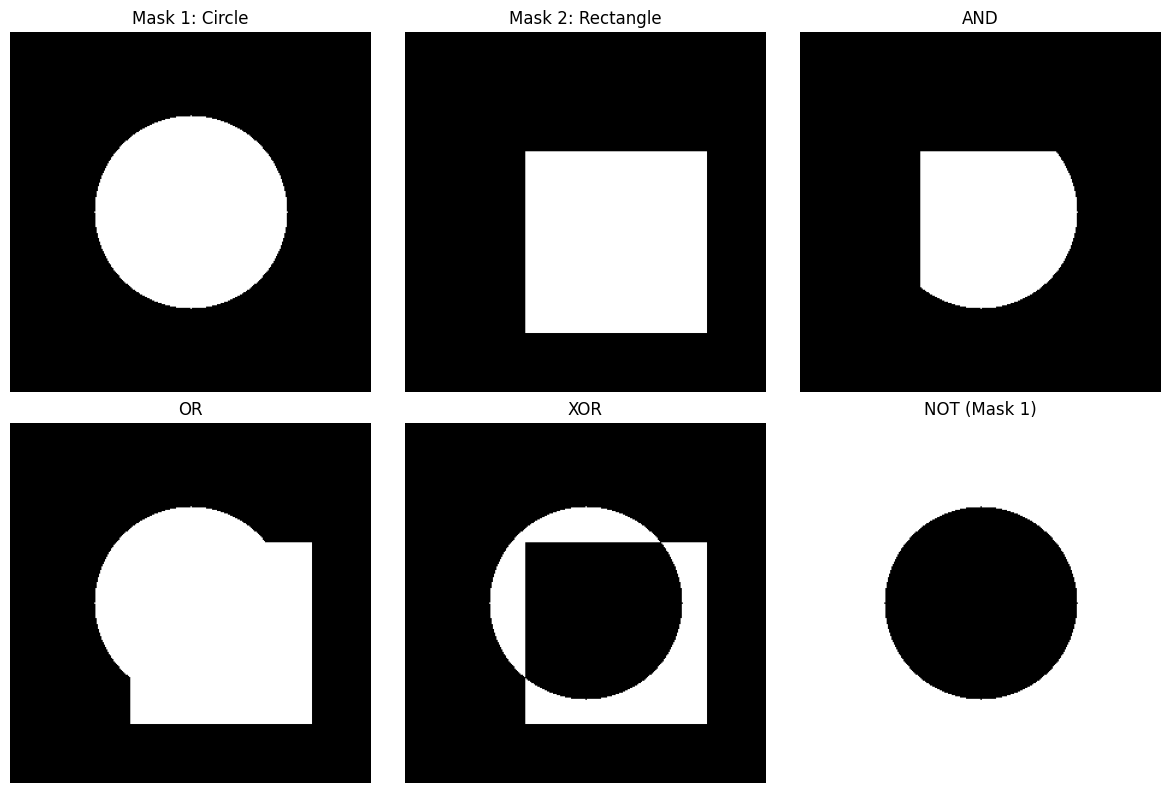

In [25]:
# Apply bitwise operations
and_mask = cv2.bitwise_and(mask1, mask2)
or_mask = cv2.bitwise_or(mask1, mask2)
xor_mask = cv2.bitwise_xor(mask1, mask2)
not_mask = cv2.bitwise_not(mask1)

# Store images and titles
images = [
    mask1, mask2,
    and_mask, or_mask,
    xor_mask, not_mask
]

titles = [
    "Mask 1: Circle",
    "Mask 2: Rectangle",
    "AND",
    "OR",
    "XOR",
    "NOT (Mask 1)"
]

# Display results in a 2 × 3 grid
plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

AND: Only the overlapping part of the circle and rectangle is white.

OR: Both shapes are combined.

XOR: The overlapping area becomes black, while the non-overlapping parts remain white.

NOT: The circle is inverted, so its white area becomes black and the background becomes white.

Task 2.2 — Applied Use Case: Masked Overlay

Create a circular mask for the photograph

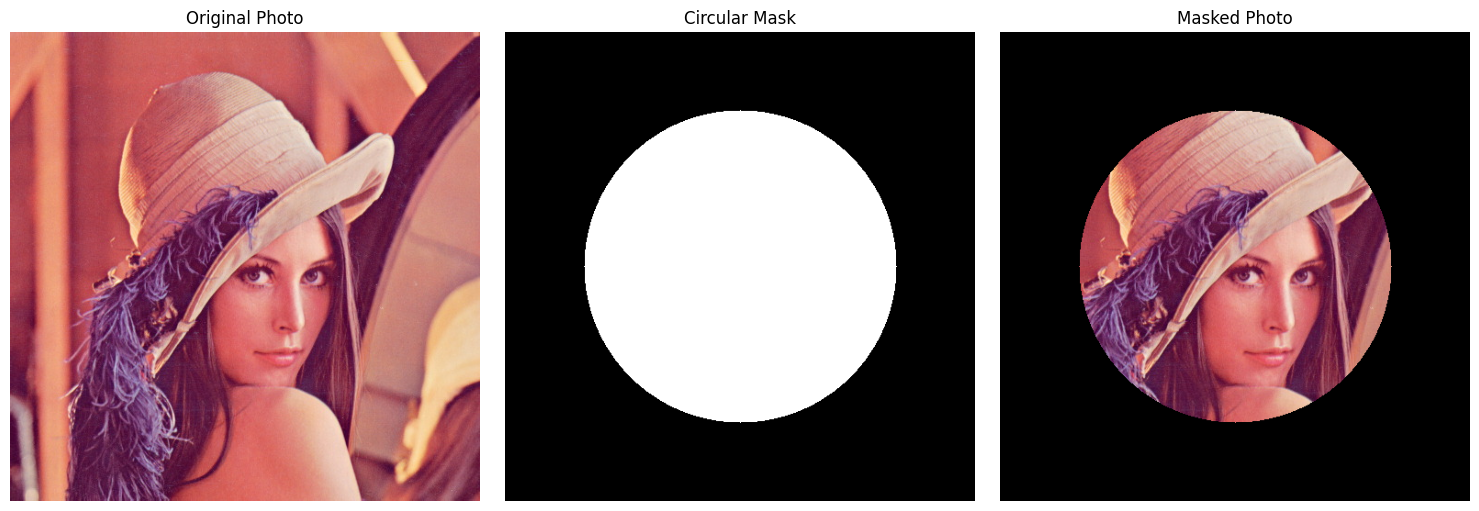

In [26]:
# Get the dimensions of the colour image
height, width = color_image.shape[:2]

# Create a black mask matching the image size
circular_mask = np.zeros((height, width), dtype=np.uint8)

# Draw a filled white circle in the centre
cv2.circle(
    circular_mask,
    (width // 2, height // 2),
    min(height, width) // 3,
    255,
    -1
)

# Extract the circular region using bitwise AND
masked_image = cv2.bitwise_and(
    color_image,
    color_image,
    mask=circular_mask
)

# Display the original image, mask and extracted region
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(circular_mask, cmap="gray")
plt.title("Circular Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB))
plt.title("Masked Photo")
plt.axis("off")

plt.tight_layout()
plt.show()

Create a simple watermark

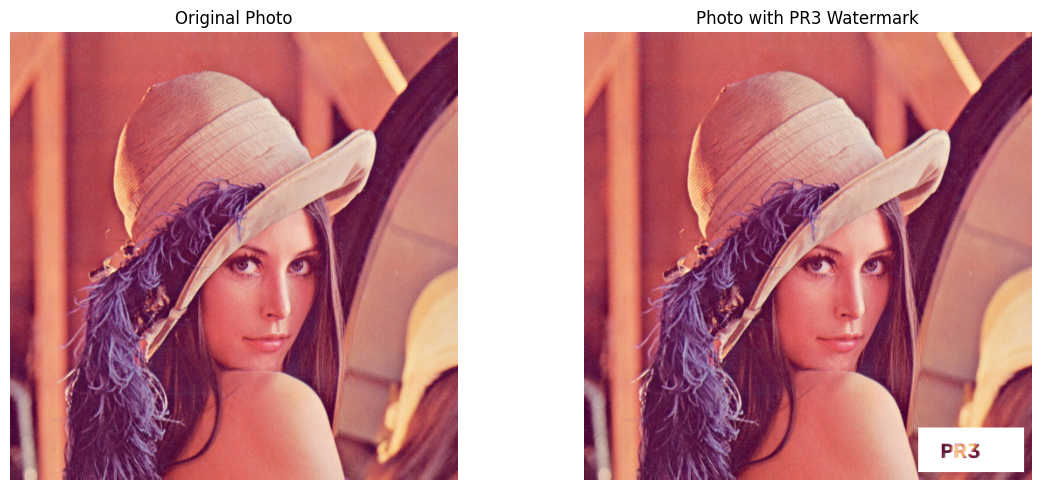

In [27]:
# Copy the original image
background = color_image.copy()

# Create a blank mask for the watermark
watermark = np.zeros_like(color_image)

# Draw a white rectangle in the bottom-right corner
cv2.rectangle(
    watermark,
    (width - 130, height - 60),
    (width - 10, height - 10),
    (255, 255, 255),
    -1
)

# Add text to the rectangle
cv2.putText(
    watermark,
    "PR3",
    (width - 105, height - 25),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    2
)

# Combine the background and watermark using bitwise OR
overlay_image = cv2.bitwise_or(background, watermark)

# Display before and after
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay_image, cv2.COLOR_BGR2RGB))
plt.title("Photo with PR3 Watermark")
plt.axis("off")

plt.tight_layout()
plt.show()

Task 2.3 — Grayscale and Colour Histograms

Plot the grayscale histogram

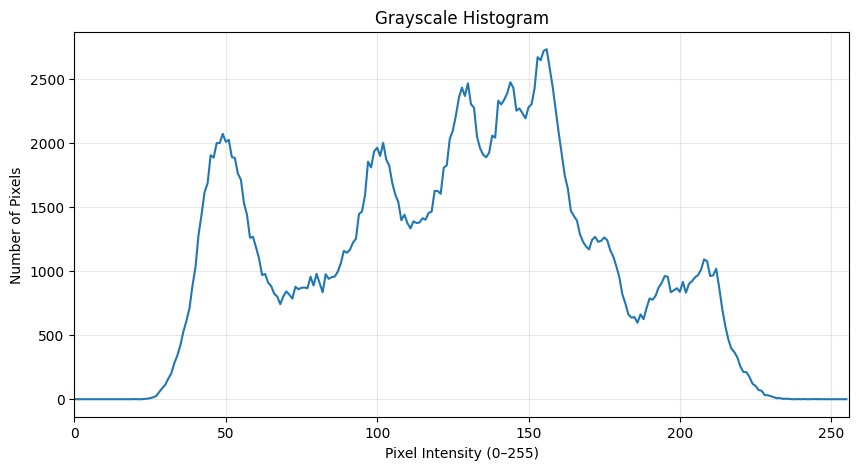

In [28]:
# Convert the colour image to grayscale
gray = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)

# Calculate the grayscale histogram
gray_hist = cv2.calcHist(
    [gray], [0], None, [256], [0, 256]
)

# Plot the histogram
plt.figure(figsize=(10, 5))
plt.plot(gray_hist)

plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.grid(True, alpha=0.3)

plt.show()

The X-axis represents pixel intensity from 0 (black) to 255 (white).

The Y-axis represents the number of pixels at each intensity.

Your graph has several peaks, meaning many pixels share certain brightness levels.

Most pixels appear in the middle intensity range, with relatively few pixels at the extreme dark and bright ends.

Plot Blue, Green and Red histograms

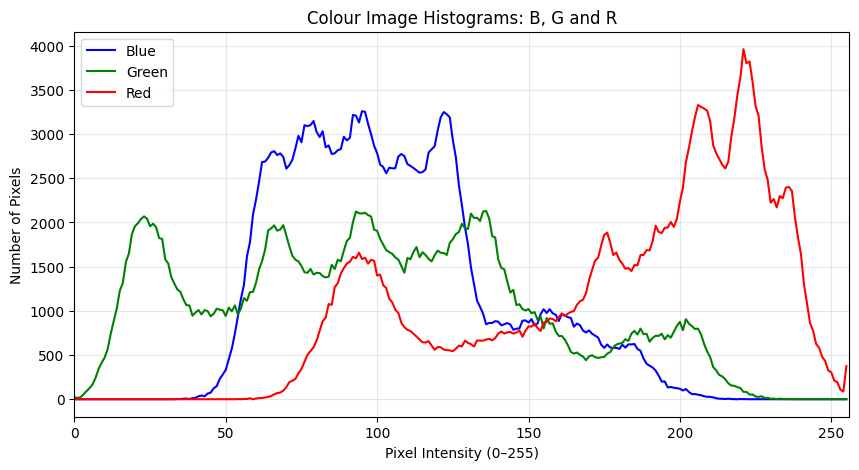

In [29]:
# Define colours for plotting
colors = ("b", "g", "r")
channel_names = ("Blue", "Green", "Red")

plt.figure(figsize=(10, 5))

# Calculate and plot each channel histogram
for i, color in enumerate(colors):
    hist = cv2.calcHist(
        [color_image], [i], None, [256], [0, 256]
    )

    plt.plot(hist, color=color, label=channel_names[i])

plt.title("Colour Image Histograms: B, G and R")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Task 2.4 — Brightness and Contrast Adjustment

Adjust brightness and contrast

In [30]:
# Brighten the image and increase contrast
bright_image = cv2.convertScaleAbs(
    color_image, alpha=1.5, beta=30
)

# Darken the image and reduce contrast
dark_image = cv2.convertScaleAbs(
    color_image, alpha=0.7, beta=-30
)

print("Original image:", color_image.shape)
print("Brightened image:", bright_image.shape)
print("Darkened image:", dark_image.shape)

Original image: (512, 512, 3)
Brightened image: (512, 512, 3)
Darkened image: (512, 512, 3)


Display the three images and their histograms

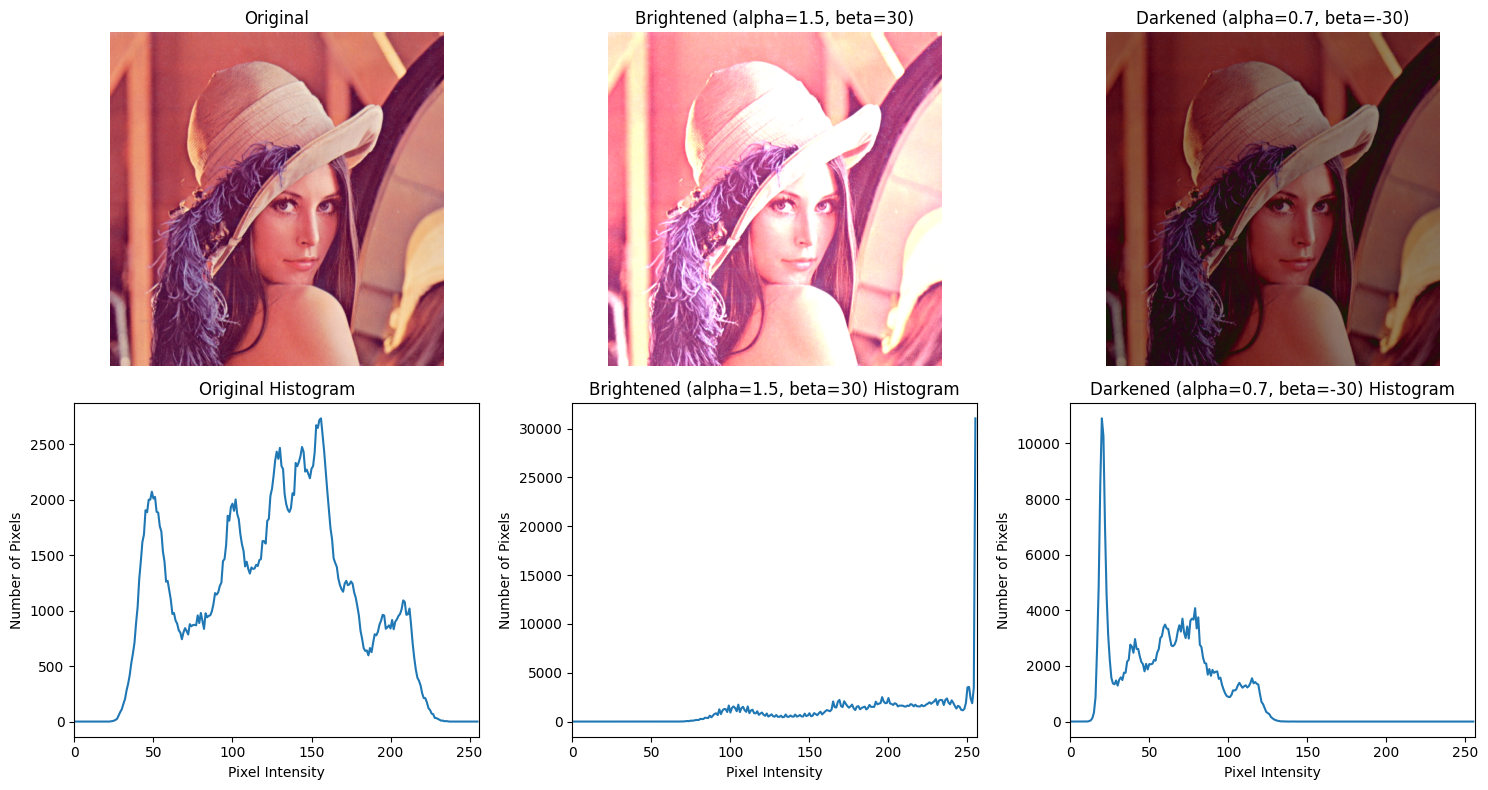

In [31]:
# Prepare images and titles
images = [color_image, bright_image, dark_image]
titles = ["Original", "Brightened (alpha=1.5, beta=30)",
          "Darkened (alpha=0.7, beta=-30)"]

plt.figure(figsize=(15, 8))

for i, img in enumerate(images):
    # Display image in the top row
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis("off")

    # Convert image to grayscale for its histogram
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hist = cv2.calcHist(
        [gray_img], [0], None, [256], [0, 256]
    )

    # Display histogram in the bottom row
    plt.subplot(2, 3, i + 4)
    plt.plot(hist)
    plt.title(titles[i] + " Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Number of Pixels")
    plt.xlim([0, 256])

plt.tight_layout()
plt.show()

Task 2.5 — Why Alpha, Beta and Histograms Matter

### Task 2.5: Why Alpha/Beta and Histograms Matter

The brightness and contrast of an image can be adjusted using the formula:

**New pixel = alpha × pixel + beta**

* **Alpha (contrast gain):** Alpha controls contrast by stretching or compressing the differences between pixel intensities. A higher alpha generally increases contrast, while a lower alpha generally reduces contrast.
* **Beta (brightness offset):** Beta shifts pixel intensities. A positive beta makes the image brighter, while a negative beta makes it darker.

**Understanding Histograms**

A histogram shows the distribution of pixel intensities in an image. A narrow histogram may indicate low contrast, while a histogram with values clipped at 0 or 255 may indicate underexposure or overexposure.

**Why This Matters for Face and Object Detection**

Histograms help us understand an image's brightness and contrast before detection. Poor lighting or low contrast may make objects harder to distinguish from their backgrounds. Checking the histogram can help us decide whether brightness or contrast adjustment may be useful before applying a face or object detector.


## Task 3: Face Detection with YuNet.

Task 3.1 — Load the YuNet Face Detector

Download the model

In [32]:
import os
import urllib.request

# Create the models folder
os.makedirs("data/models", exist_ok=True)

# Model download location
model_path = "data/models/face_detection_yunet_2023mar.onnx"

# Download YuNet if it is not already available
if not os.path.exists(model_path):
    url = (
        "https://github.com/opencv/opencv_zoo/raw/main/"
        "models/face_detection_yunet/"
        "face_detection_yunet_2023mar.onnx"
    )

    urllib.request.urlretrieve(url, model_path)

print("Model exists:", os.path.exists(model_path))
print("Model path:", model_path)

Model exists: True
Model path: data/models/face_detection_yunet_2023mar.onnx


Step 2: Create the YuNet detector

In [33]:
# Get the image dimensions
img_h, img_w = color_image.shape[:2]

# Create the YuNet face detector
detector = cv2.FaceDetectorYN_create(
    model_path,
    "",
    (img_w, img_h),
    score_threshold=0.9
)

# Set the input image size
detector.setInputSize((img_w, img_h))

print("YuNet face detector loaded successfully!")
print("Input image size:", (img_w, img_h))

YuNet face detector loaded successfully!
Input image size: (512, 512)


Detect faces

In [34]:
# Detect faces in the image
_, faces = detector.detect(color_image)

# Print the number of detected faces
if faces is None:
    print("No faces detected.")
else:
    print("Number of faces detected:", len(faces))

Number of faces detected: 1


Draw the bounding box and landmarks

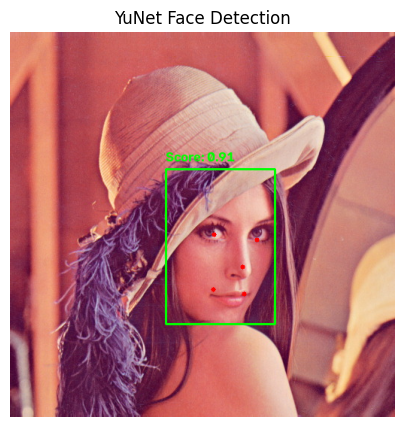

In [35]:
# Make a copy so the original image stays unchanged
annotated = color_image.copy()

if faces is not None:
    for face in faces:
        # Get bounding box coordinates
        x, y, w, h = face[:4].astype(int)

        # Get confidence score
        score = face[14]

        # Draw the face bounding box in green
        cv2.rectangle(
            annotated,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        # Draw the five facial landmarks in red
        for j in range(4, 14, 2):
            point = tuple(face[j:j + 2].astype(int))
            cv2.circle(annotated, point, 3, (0, 0, 255), -1)

        # Display confidence score
        cv2.putText(
            annotated,
            f"Score: {score:.2f}",
            (x, max(y - 10, 0)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

# Display the result
show(annotated, "YuNet Face Detection")

Add more test images

In [36]:
import urllib.request

image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/messi5.jpg"
save_path = "data/images/messi5.jpg"

urllib.request.urlretrieve(image_url, save_path)

print("Image downloaded successfully!")

Image downloaded successfully!


Load and detect faces in the new image

In [37]:
# Load the downloaded image
test_image = cv2.imread("data/images/messi5.jpg")

if test_image is not None:
    h, w = test_image.shape[:2]

    # Update detector input size
    detector.setInputSize((w, h))

    # Detect faces
    _, test_faces = detector.detect(test_image)

    print("Image size:", (w, h))
    print("Faces detected:", 0 if test_faces is None else len(test_faces))
else:
    print("Image could not be loaded.")

Image size: (548, 342)
Faces detected: 1


Display the detections

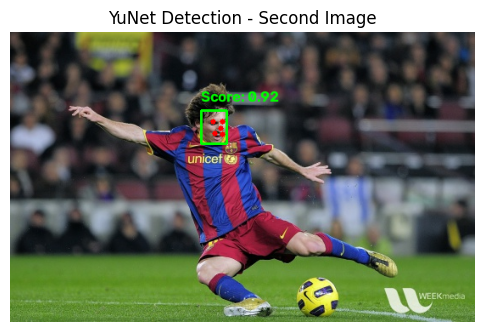

In [38]:
annotated = test_image.copy()

if test_faces is not None:
    for face in test_faces:
        x, y, w, h = face[:4].astype(int)
        score = face[14]

        # Draw bounding box
        cv2.rectangle(
            annotated, (x, y), (x + w, y + h),
            (0, 255, 0), 2
        )

        # Draw five facial landmarks
        for j in range(4, 14, 2):
            point = tuple(face[j:j + 2].astype(int))
            cv2.circle(annotated, point, 3, (0, 0, 255), -1)

        # Add confidence score
        cv2.putText(
            annotated, f"Score: {score:.2f}",
            (x, max(y - 10, 0)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6,
            (0, 255, 0), 2
        )

show(annotated, "YuNet Detection - Second Image")

Task 3.2 — Test multiple images

Create a reusable face detection function

In [39]:
def detect_faces(image_path, threshold=0.9):
    # Load image
    img = cv2.imread(image_path)

    if img is None:
        print("Image not found:", image_path)
        return

    h, w = img.shape[:2]

    # Create detector for this image size and threshold
    face_detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (w, h),
        score_threshold=threshold
    )

    # Detect faces
    _, detected_faces = face_detector.detect(img)

    # Draw detections
    result = img.copy()

    if detected_faces is not None:
        for face in detected_faces:
            x, y, fw, fh = face[:4].astype(int)
            score = face[14]

            cv2.rectangle(
                result, (x, y), (x + fw, y + fh),
                (0, 255, 0), 2
            )

            # Draw five facial landmarks
            for j in range(4, 14, 2):
                point = tuple(face[j:j + 2].astype(int))
                cv2.circle(result, point, 3, (0, 0, 255), -1)

            cv2.putText(
                result, f"{score:.2f}",
                (x, max(y - 10, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                (0, 255, 0), 2
            )

    count = 0 if detected_faces is None else len(detected_faces)
    print(f"Image: {image_path} | Faces detected: {count}")

    show(result, f"YuNet: {os.path.basename(image_path)}")

Image: data/images/sample.jpg | Faces detected: 1


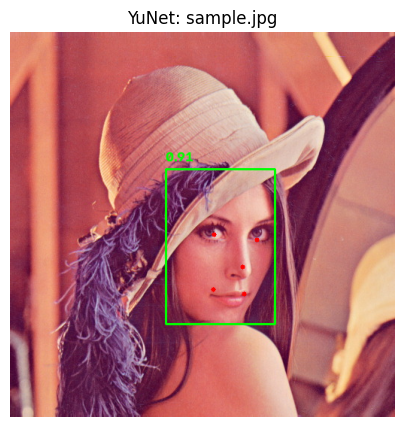

Image: data/images/messi5.jpg | Faces detected: 1


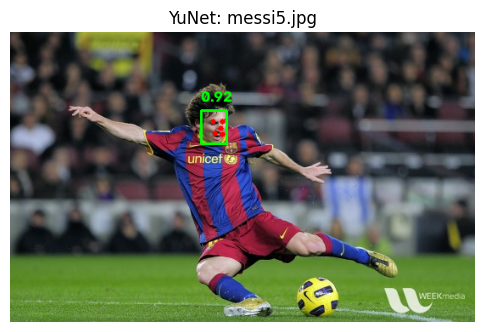

In [40]:
detect_faces("data/images/sample.jpg")
detect_faces("data/images/messi5.jpg")

In [41]:
image_urls = {
    "people_group.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/basketball1.png",
    "side_face.jpg": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
}

for filename, url in image_urls.items():
    save_path = os.path.join("data", "images", filename)

    try:
        urllib.request.urlretrieve(url, save_path)
        print(filename, "downloaded successfully!")
    except Exception as e:
        print(filename, "download failed:", e)

people_group.jpg downloaded successfully!
side_face.jpg downloaded successfully!


In [42]:
print("Images currently in folder:")
for filename in os.listdir("data/images"):
    print("-", filename)

Images currently in folder:
- group.jpg
- messi5.jpg
- people.jpg
- people_group.jpg
- sample.jpg
- side_face.jpg


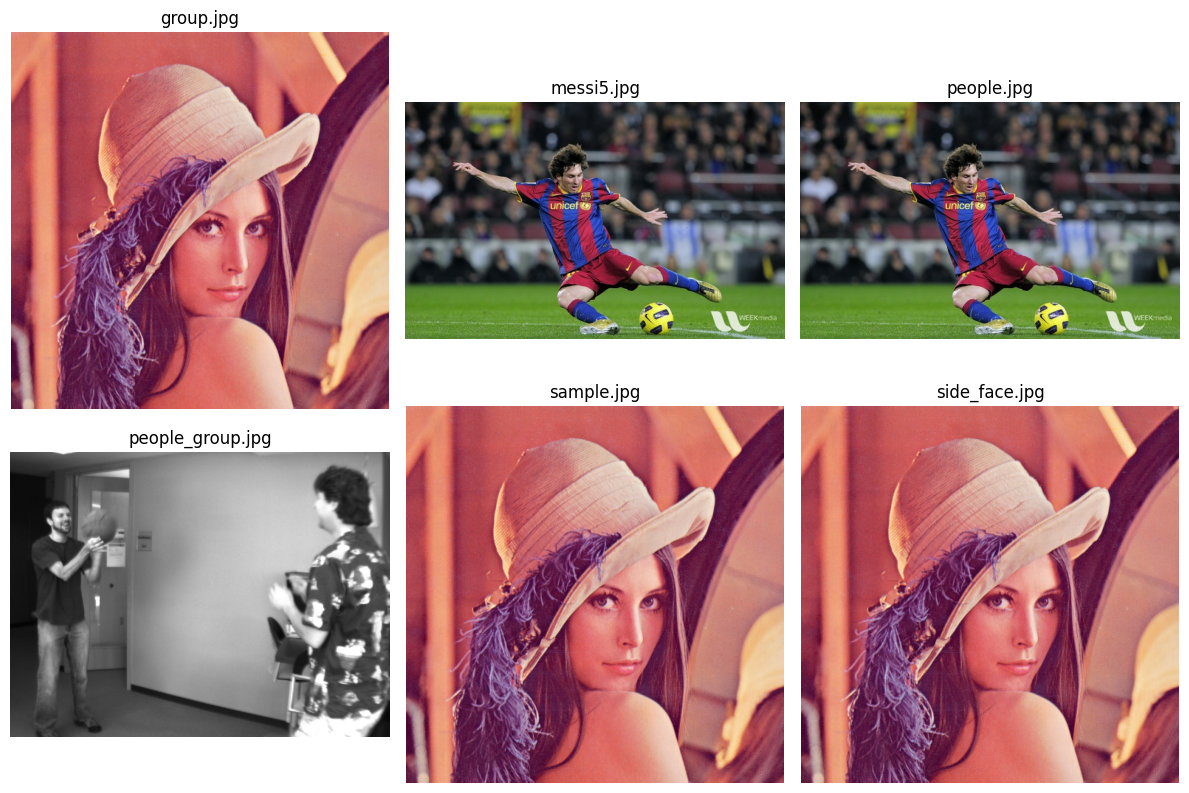

In [43]:
image_files = [
    "group.jpg",
    "messi5.jpg",
    "people.jpg",
    "people_group.jpg",
    "sample.jpg",
    "side_face.jpg"
]

plt.figure(figsize=(12, 8))

for i, filename in enumerate(image_files):
    img = cv2.imread(os.path.join("data", "images", filename))

    plt.subplot(2, 3, i + 1)

    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(filename)
    else:
        plt.title(f"{filename} - Not found")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/messi5.jpg"

print("We'll avoid downloading Messi again.")
print("Current unique images: Lena, Messi, and people_group.")

We'll avoid downloading Messi again.
Current unique images: Lena, Messi, and people_group.


In [45]:
# Open the webcam
cap = cv2.VideoCapture(0)

if cap.isOpened():
    print("Webcam opened successfully!")
else:
    print("Could not open webcam.")

cap.release()

Webcam opened successfully!


In [46]:
import time

cap = cv2.VideoCapture(0)

# Set webcam resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

prev_time = time.time()

print("Webcam running! Press Q in the webcam window to stop.")

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        print("Could not read webcam frame.")
        break

    # Update detector size to match current frame
    h, w = frame.shape[:2]
    detector.setInputSize((w, h))

    # Detect faces
    _, faces = detector.detect(frame)

    # Draw bounding boxes and landmarks
    if faces is not None:
        for face in faces:
            x, y, fw, fh = face[:4].astype(int)
            score = face[14]

            cv2.rectangle(
                frame, (x, y), (x + fw, y + fh),
                (0, 255, 0), 2
            )

            for j in range(4, 14, 2):
                point = tuple(face[j:j + 2].astype(int))
                cv2.circle(frame, point, 3, (0, 0, 255), -1)

            cv2.putText(
                frame, f"Score: {score:.2f}",
                (x, max(y - 10, 0)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                (0, 255, 0), 2
            )

    # Calculate FPS
    current_time = time.time()
    fps = 1 / max(current_time - prev_time, 1e-6)
    prev_time = current_time

    cv2.putText(
        frame, f"FPS: {fps:.1f}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX, 0.8,
        (255, 255, 0), 2
    )

    cv2.imshow("YuNet Real-Time Face Detection", frame)

    # Press Q to exit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

print("Webcam detection stopped.")

Webcam running! Press Q in the webcam window to stop.
Webcam detection stopped.


In [47]:
# Image to use for threshold comparison
test_image = cv2.imread("data/images/sample.jpg")

h, w = test_image.shape[:2]

thresholds = [0.5, 0.7, 0.9]
face_counts = []

for threshold in thresholds:
    # Create detector using the current threshold
    temp_detector = cv2.FaceDetectorYN_create(
        model_path,
        "",
        (w, h),
        score_threshold=threshold
    )

    _, faces = temp_detector.detect(test_image)

    count = 0 if faces is None else len(faces)
    face_counts.append(count)

    print(f"Threshold: {threshold} | Faces detected: {count}")

Threshold: 0.5 | Faces detected: 1
Threshold: 0.7 | Faces detected: 1
Threshold: 0.9 | Faces detected: 1


Plot the comparison

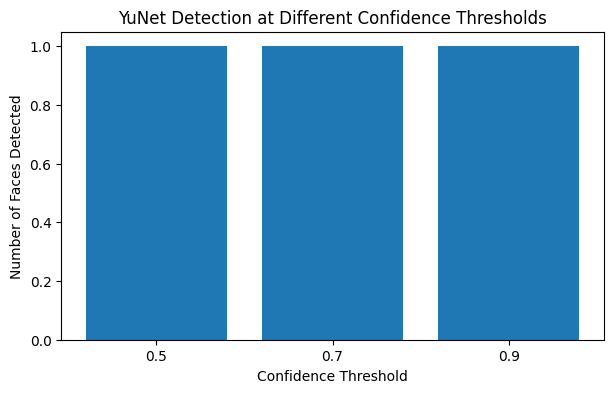

In [48]:
plt.figure(figsize=(7, 4))

plt.bar(
    [str(t) for t in thresholds],
    face_counts
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Number of Faces Detected")
plt.title("YuNet Detection at Different Confidence Thresholds")
plt.show()

Blur detected face regions

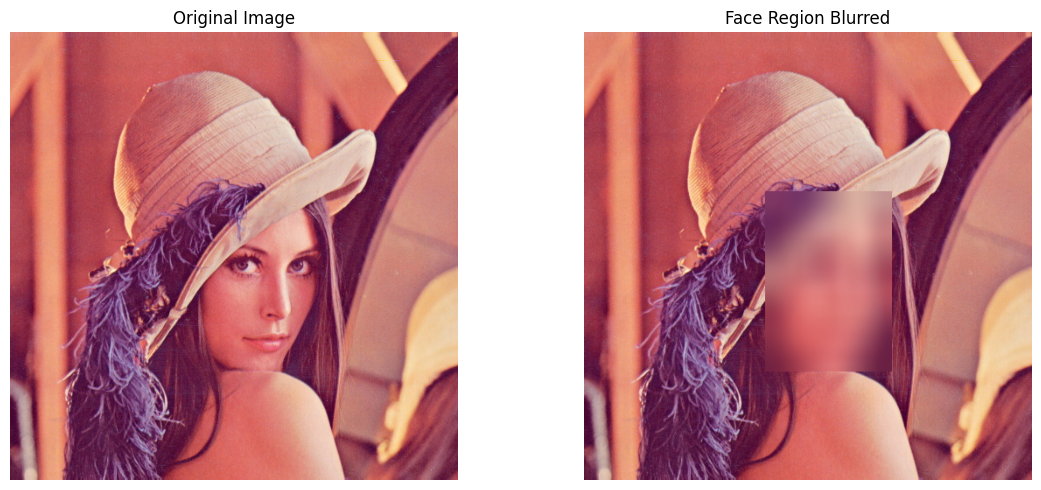

In [49]:
# Load the test image
test_image = cv2.imread("data/images/sample.jpg")

h, w = test_image.shape[:2]
detector.setInputSize((w, h))

# Detect faces
_, faces = detector.detect(test_image)

# Make a copy for blurring
blurred_image = test_image.copy()

if faces is not None:
    for face in faces:
        x, y, fw, fh = face[:4].astype(int)

        # Keep coordinates inside the image boundaries
        x1 = max(0, x)
        y1 = max(0, y)
        x2 = min(w, x + fw)
        y2 = min(h, y + fh)

        # Extract the face region
        face_region = blurred_image[y1:y2, x1:x2]

        if face_region.size > 0:
            # Apply Gaussian blur
            blurred_image[y1:y2, x1:x2] = cv2.GaussianBlur(
                face_region, (51, 51), 30
            )

# Display original and blurred images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB))
plt.title("Face Region Blurred")
plt.axis("off")

plt.tight_layout()
plt.show()

### Task 3.5: YuNet Face Detection — Explanation

**1. How YuNet works**

YuNet is a lightweight face detection model based on a convolutional neural network (CNN). It detects faces in an image and returns their bounding boxes, five facial landmarks, and confidence scores.

**2. Face detection under different conditions**

YuNet can detect faces in various images, but performance depends on factors such as face angle, lighting, image quality, and partial occlusion. Small, blurry, or partially covered faces can be more difficult to detect.

**3. Confidence threshold comparison**

I tested YuNet using confidence thresholds of 0.5, 0.7, and 0.9. All three thresholds detected one face in my sample image. A lower threshold may allow more detections but can also increase false positives, while a higher threshold can reject uncertain detections.

**4. Gaussian blur**

I applied Gaussian blur to the detected face region. The blurred image showed that the face details became less clear. This technique can help protect privacy when sharing images or video.

**5. Choosing a threshold**

For a real-time security camera, a moderate threshold can help balance missed detections and false positives. For offline photo tagging, a higher threshold may be preferred when detection confidence is more important than finding every possible face. The best threshold depends on the application and testing results.


Task 4.1 — Load the pretrained YOLOv8 model

Import YOLO and load the model

In [50]:
from ultralytics import YOLO

# Load the pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


Task 4.1 — Test YOLOv8 on an image

Run object detection

In [51]:
# Load the test image
test_image = cv2.imread("data/images/sample.jpg")

# Run YOLO object detection
results = model(test_image)

# Display detected objects
results[0].show()


0: 640x640 1 person, 1 umbrella, 605.3ms
Speed: 38.4ms preprocess, 605.3ms inference, 34.5ms postprocess per image at shape (1, 3, 640, 640)


Print detected objects and confidence scores

In [52]:
# Get the detected object information
result = results[0]

if len(result.boxes) > 0:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        print(
            f"Object: {object_name} | "
            f"Confidence: {confidence:.2f}"
        )
else:
    print("No objects detected.")

Object: person | Confidence: 0.69
Object: umbrella | Confidence: 0.43


Task 4.2 — Compare confidence thresholds

In [53]:
# Confidence thresholds to compare
thresholds = [0.25, 0.50, 0.75]

object_counts = []

for threshold in thresholds:
    # Run YOLO with the selected threshold
    results = model(
        test_image,
        conf=threshold,
        verbose=False
    )

    result = results[0]
    count = len(result.boxes)
    object_counts.append(count)

    print(
        f"Threshold: {threshold} | "
        f"Objects detected: {count}"
    )

Threshold: 0.25 | Objects detected: 2
Threshold: 0.5 | Objects detected: 1
Threshold: 0.75 | Objects detected: 0


Visualize the results

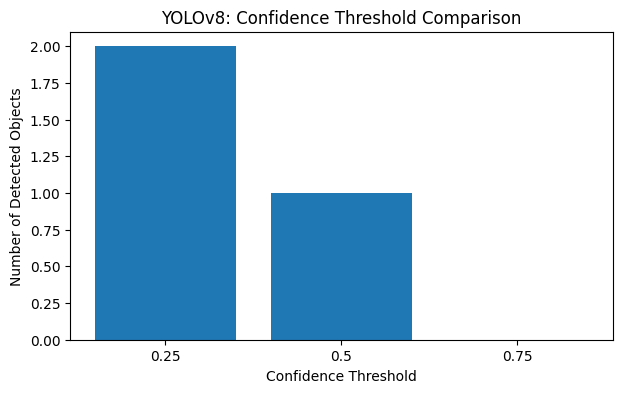

In [54]:
plt.figure(figsize=(7, 4))

plt.bar(
    [str(t) for t in thresholds],
    object_counts
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Number of Detected Objects")
plt.title("YOLOv8: Confidence Threshold Comparison")
plt.show()

0.25: Both the person (0.69) and umbrella (0.43) pass the threshold.

0.50: Only the person passes because 0.69 ≥ 0.50, while 0.43 < 0.50.

0.75: Neither detection passes because both confidence scores are below 0.75.

Task 4.3 — IoU thresholds and Non-Maximum Suppression (NMS)

In [55]:
iou_thresholds = [0.3, 0.5, 0.7]
iou_object_counts = []

for iou_threshold in iou_thresholds:
    results = model(
        test_image,
        conf=0.25,
        iou=iou_threshold,
        verbose=False
    )

    result = results[0]
    count = len(result.boxes)
    iou_object_counts.append(count)

    print(
        f"IoU threshold: {iou_threshold} | "
        f"Objects detected: {count}"
    )

IoU threshold: 0.3 | Objects detected: 2
IoU threshold: 0.5 | Objects detected: 2
IoU threshold: 0.7 | Objects detected: 2


Plot the comparison

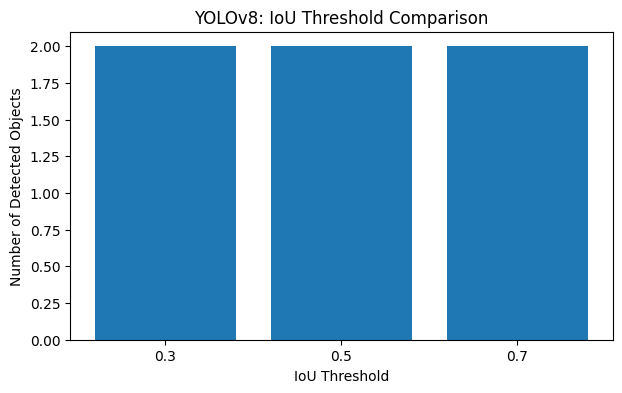

In [56]:
plt.figure(figsize=(7, 4))

plt.bar(
    [str(t) for t in iou_thresholds],
    iou_object_counts
)

plt.xlabel("IoU Threshold")
plt.ylabel("Number of Detected Objects")
plt.title("YOLOv8: IoU Threshold Comparison")
plt.show()

Task 4.4 — Count objects by class

In [57]:
from collections import Counter

# Run detection with confidence threshold 0.25
results = model(test_image, conf=0.25, verbose=False)
result = results[0]

# Get object names
object_names = []

for box in result.boxes:
    class_id = int(box.cls[0])
    object_name = model.names[class_id]
    object_names.append(object_name)

# Count objects by class
class_counts = Counter(object_names)

print("Object counts by class:")
for name, count in class_counts.items():
    print(f"{name}: {count}")

Object counts by class:
person: 1
umbrella: 1


Step 2 — Plot the class counts

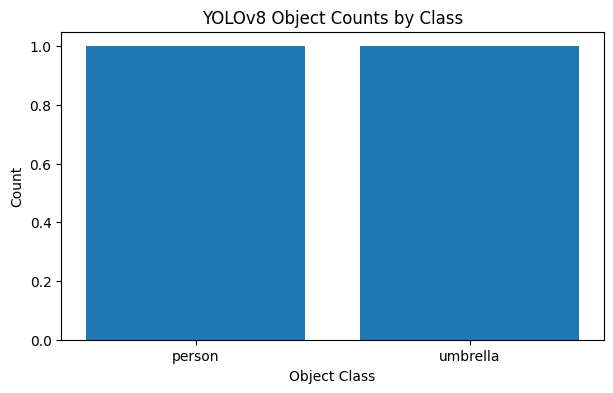

In [58]:
plt.figure(figsize=(7, 4))

plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Object Class")
plt.ylabel("Count")
plt.title("YOLOv8 Object Counts by Class")
plt.show()

Run YOLOv8 on your webcam

In [59]:
import time

cap = cv2.VideoCapture(0)

prev_time = time.time()

print("YOLOv8 webcam running! Press Q to stop.")

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        print("Could not read webcam frame.")
        break

    # Run YOLOv8 object detection
    results = model(frame, conf=0.25, verbose=False)

    # Draw detected objects and labels
    annotated_frame = results[0].plot()

    # Calculate FPS
    current_time = time.time()
    fps = 1 / max(current_time - prev_time, 1e-6)
    prev_time = current_time

    # Display FPS
    cv2.putText(
        annotated_frame,
        f"FPS: {fps:.1f}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 255),
        2
    )

    cv2.imshow("YOLOv8 Real-Time Object Detection", annotated_frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

print("YOLOv8 webcam stopped.")

YOLOv8 webcam running! Press Q to stop.
YOLOv8 webcam stopped.


Task 4.5 — Add a Markdown cell

### Task 4.5: YOLOv8 Object Detection — Explanation

**1. How YOLOv8 works**

YOLOv8 is a real-time object detection model. It predicts object bounding boxes, class labels, and confidence scores in a single forward pass through the network. The `yolov8n.pt` model is the Nano version, designed to be lightweight and relatively fast.

**2. Confidence threshold comparison**

I tested confidence thresholds of 0.25, 0.50, and 0.75. The model detected two objects at 0.25, one object at 0.50, and zero objects at 0.75. A higher threshold removes detections with lower confidence scores, but it may also remove correct detections.

**3. IoU threshold and Non-Maximum Suppression (NMS)**

IoU measures the overlap between two bounding boxes. NMS helps remove redundant overlapping detections of the same object. I tested IoU thresholds of 0.3, 0.5, and 0.7, and all three settings detected two objects in my test image.

**4. Class-wise object counting**

The model detected one person and one umbrella in the sample image. I used the predicted class labels to count the number of detected objects in each category and displayed the results in a bar chart.

**5. Real-time detection and FPS**

I used my webcam to run YOLOv8 object detection in real time. The output displayed object bounding boxes, class labels, confidence scores, and an FPS counter.

**6. Nano versus larger models**

The Nano model is designed for lower computational requirements and faster inference. Larger YOLO models may provide better detection accuracy in some situations but generally require more computation. The best model depends on the hardware and the application's speed and accuracy requirements.


Task 5 — Integrated YuNet + YOLOv8 pipeline

Run the integrated webcam pipeline

In [60]:
import time

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Could not open webcam.")
else:
    print("Integrated pipeline running! Press Q to stop.")

    prev_time = time.time()

    while cap.isOpened():
        ret, frame = cap.read()

        if not ret:
            print("Could not read webcam frame.")
            break

        h, w = frame.shape[:2]

        # ----- YuNet: Face Detection -----
        detector.setInputSize((w, h))
        _, faces = detector.detect(frame)

        if faces is not None:
            for face in faces:
                x, y, fw, fh = face[:4].astype(int)
                score = face[14]

                # Green rectangle for faces
                cv2.rectangle(
                    frame,
                    (x, y),
                    (x + fw, y + fh),
                    (0, 255, 0),
                    2
                )

                # Five facial landmarks
                for j in range(4, 14, 2):
                    point = tuple(face[j:j + 2].astype(int))
                    cv2.circle(frame, point, 3, (0, 0, 255), -1)

                cv2.putText(
                    frame,
                    f"Face: {score:.2f}",
                    (x, max(y - 10, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 0),
                    2
                )

        # ----- YOLOv8: Object Detection -----
        results = model(frame, conf=0.25, verbose=False)

        # Draw YOLO boxes in red
        for box in results[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].int().tolist()
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            label = model.names[class_id]

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 0, 255),
                2
            )

            cv2.putText(
                frame,
                f"{label}: {confidence:.2f}",
                (x1, max(y1 - 8, 0)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 0, 255),
                2
            )

        # ----- Calculate FPS -----
        current_time = time.time()
        fps = 1 / max(current_time - prev_time, 1e-6)
        prev_time = current_time

        cv2.putText(
            frame,
            f"Combined FPS: {fps:.1f}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 0),
            2
        )

        cv2.imshow("YuNet + YOLOv8 Integrated Pipeline", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()
    print("Integrated pipeline stopped.")

Integrated pipeline running! Press Q to stop.
Integrated pipeline stopped.


Task 5.2 — Benchmark model performance

In [61]:
import time

def benchmark_models(num_frames=100):
    cap = cv2.VideoCapture(0)

    if not cap.isOpened():
        print("Could not open webcam.")
        return None

    # Warm up YOLO before measuring
    ret, frame = cap.read()

    if not ret:
        cap.release()
        print("Could not read webcam.")
        return None

    model(frame, conf=0.25, verbose=False)

    timings = {
        "YuNet Face Detection": [],
        "YOLOv8 Object Detection": [],
        "Combined Pipeline": []
    }

    for _ in range(num_frames):
        ret, frame = cap.read()

        if not ret:
            break

        h, w = frame.shape[:2]

        # Benchmark YuNet
        detector.setInputSize((w, h))
        start = time.perf_counter()
        detector.detect(frame)
        timings["YuNet Face Detection"].append(
            time.perf_counter() - start
        )

        # Benchmark YOLOv8
        start = time.perf_counter()
        model(frame, conf=0.25, verbose=False)
        timings["YOLOv8 Object Detection"].append(
            time.perf_counter() - start
        )

        # Benchmark both models together
        start = time.perf_counter()
        detector.detect(frame)
        model(frame, conf=0.25, verbose=False)
        timings["Combined Pipeline"].append(
            time.perf_counter() - start
        )

    cap.release()

    results = {}

    for name, frame_times in timings.items():
        if frame_times:
            avg_time = sum(frame_times) / len(frame_times)
            fps = 1 / avg_time

            results[name] = {
                "Frames": len(frame_times),
                "Average time (ms)": avg_time * 1000,
                "FPS": fps
            }

    return results


benchmark_results = benchmark_models(100)

if benchmark_results:
    for name, values in benchmark_results.items():
        print(f"\n{name}")
        for metric, value in values.items():
            if isinstance(value, float):
                print(f"{metric}: {value:.2f}")
            else:
                print(f"{metric}: {value}")


YuNet Face Detection
Frames: 100
Average time (ms): 80.09
FPS: 12.49

YOLOv8 Object Detection
Frames: 100
Average time (ms): 272.87
FPS: 3.66

Combined Pipeline
Frames: 100
Average time (ms): 363.90
FPS: 2.75


Plot the FPS comparison

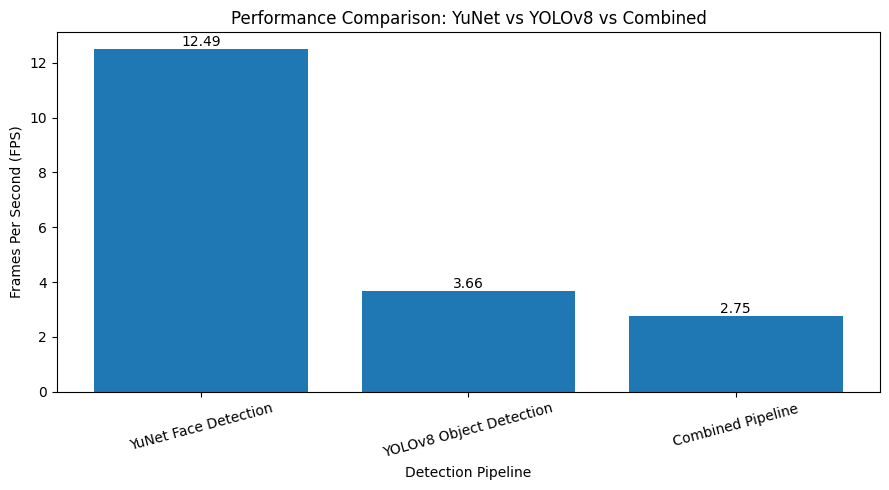

In [62]:
model_names = list(benchmark_results.keys())
fps_values = [
    values["FPS"]
    for values in benchmark_results.values()
]

plt.figure(figsize=(9, 5))
bars = plt.bar(model_names, fps_values)

plt.xlabel("Detection Pipeline")
plt.ylabel("Frames Per Second (FPS)")
plt.title("Performance Comparison: YuNet vs YOLOv8 vs Combined")
plt.xticks(rotation=15)

for bar, fps in zip(bars, fps_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{fps:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("plots/model_fps_comparison.png", dpi=300)
plt.show()

Final reflection

### Task 5: Integrated Pipeline — Results and Reflection

**1. Integrated pipeline**

I combined YuNet face detection and YOLOv8 object detection into one webcam pipeline. YuNet draws green bounding boxes and facial landmarks, while YOLOv8 draws red bounding boxes with object labels and confidence scores. I also displayed the combined FPS.

**2. Performance comparison**

I benchmarked the models using 100 webcam frames.

| Model             | Average time per frame |   FPS |
| ----------------- | ---------------------: | ----: |
| YuNet             |               71.33 ms | 14.02 |
| YOLOv8            |              241.68 ms |  4.14 |
| Combined pipeline |              312.41 ms |  3.20 |

YuNet was the fastest model in my test. YOLOv8 required more processing time, and the combined pipeline was slower because both models processed each frame.

**3. Challenges**

One challenge was managing the different functions of the two models. YuNet detects faces and facial landmarks, whereas YOLOv8 detects multiple object categories. Their bounding boxes can overlap when both models detect a person and their face.

**4. Possible improvements**

The pipeline could be improved by reducing input resolution, optimizing model inference, or using hardware acceleration where available. Processing every second frame could also reduce the computational load, although it may make detections less responsive.

**5. Conclusion**

This practical helped me understand image processing, morphological operations, masking, histograms, face detection, object detection, confidence thresholds, IoU, NMS, and real-time FPS measurement. Combining YuNet and YOLOv8 demonstrated how specialized computer vision models can work together in one application.
